In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import os

In [3]:
metadata_path = "../data/UrbanSound8K.csv"

df = pd.read_csv(metadata_path)

print(df.head())

      slice_file_name    fsID  start        end  salience  fold  classID  \
0    100032-3-0-0.wav  100032    0.0   0.317551         1     5        3   
1  100263-2-0-117.wav  100263   58.5  62.500000         1     5        2   
2  100263-2-0-121.wav  100263   60.5  64.500000         1     5        2   
3  100263-2-0-126.wav  100263   63.0  67.000000         1     5        2   
4  100263-2-0-137.wav  100263   68.5  72.500000         1     5        2   

              class  
0          dog_bark  
1  children_playing  
2  children_playing  
3  children_playing  
4  children_playing  


In [4]:
print("Dataset Shape:", df.shape)
print("Number of Classes:", df["class"].nunique())
print("Classes:", df["class"].unique())

Dataset Shape: (8732, 8)
Number of Classes: 10
Classes: ['dog_bark' 'children_playing' 'car_horn' 'air_conditioner' 'street_music'
 'gun_shot' 'siren' 'engine_idling' 'jackhammer' 'drilling']


class
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
jackhammer          1000
engine_idling       1000
drilling            1000
siren                929
car_horn             429
gun_shot             374
Name: count, dtype: int64


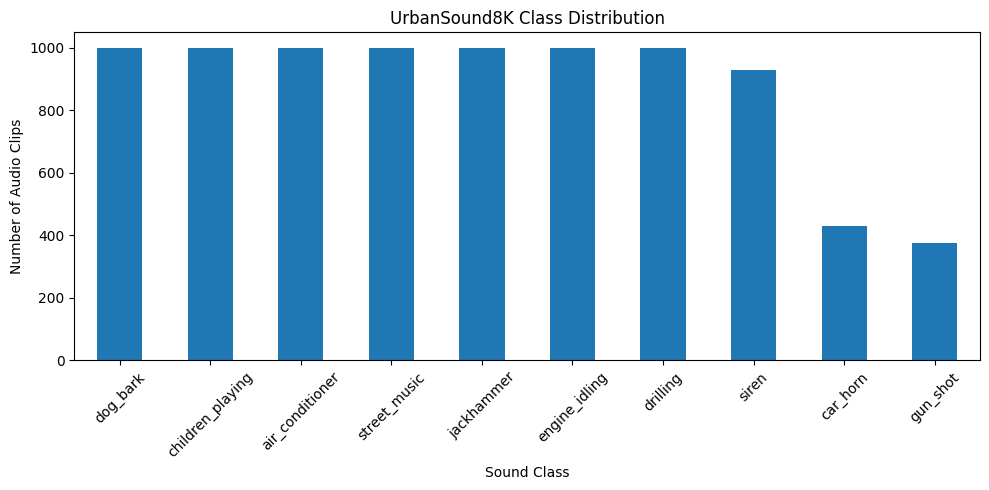

In [4]:
class_counts = df["class"].value_counts()

print(class_counts)

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")

plt.title("UrbanSound8K Class Distribution")
plt.xlabel("Sound Class")
plt.ylabel("Number of Audio Clips")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../results/class_distribution.png", dpi=300)
plt.show()

In [5]:
audio_file = None

for fold in range(1, 11):
    folder = f"../data/fold{fold}"

    if os.path.exists(folder):
        for file in os.listdir(folder):
            if file.endswith(".wav"):
                audio_file = os.path.join(folder, file)
                break

    if audio_file:
        break

print("Audio file:", audio_file)

Audio file: ../data/fold1\101415-3-0-2.wav


In [6]:
filename = os.path.basename(audio_file)

audio_info = df[df["slice_file_name"] == filename]

print(audio_info[[
    "slice_file_name",
    "classID",
    "class"
]])

     slice_file_name  classID     class
64  101415-3-0-2.wav        3  dog_bark


In [7]:
audio, sample_rate = librosa.load(
    audio_file,
    sr=None
)

print("Sample Rate:", sample_rate)
print("Samples:", len(audio))
print("Duration:", len(audio) / sample_rate, "seconds")

C:\Users\Shruti\PycharmProjects\PythonProject6\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sample Rate: 48000
Samples: 192000
Duration: 4.0 seconds


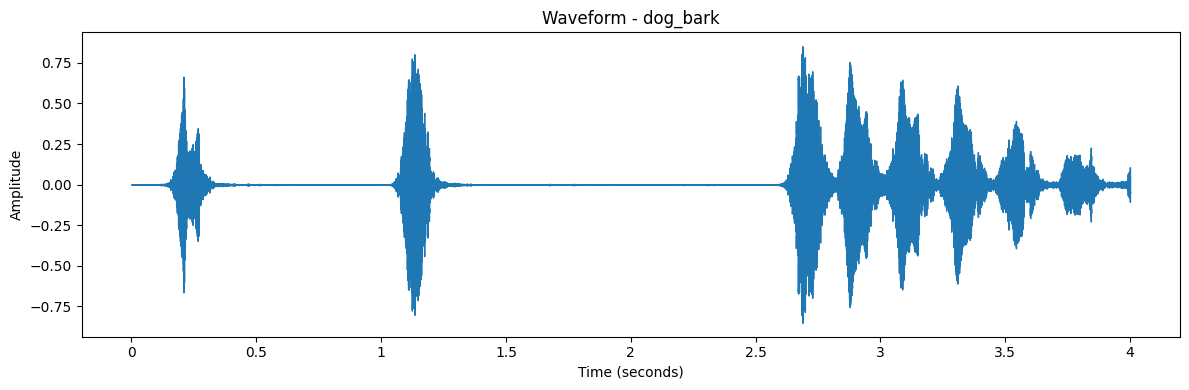

In [8]:
plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    audio,
    sr=sample_rate
)

plt.title(f"Waveform - {audio_info['class'].iloc[0]}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

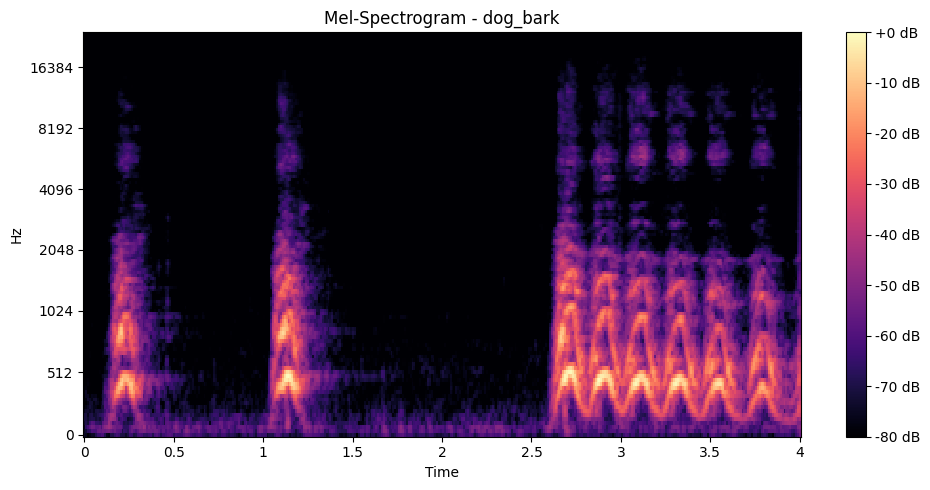

In [9]:
mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sample_rate,
    n_mels=128
)

mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mel_db,
    sr=sample_rate,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")

plt.title(
    f"Mel-Spectrogram - {audio_info['class'].iloc[0]}"
)

plt.tight_layout()
plt.show()

In [10]:
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=40
)

print("MFCC Shape:", mfcc.shape)

MFCC Shape: (40, 376)


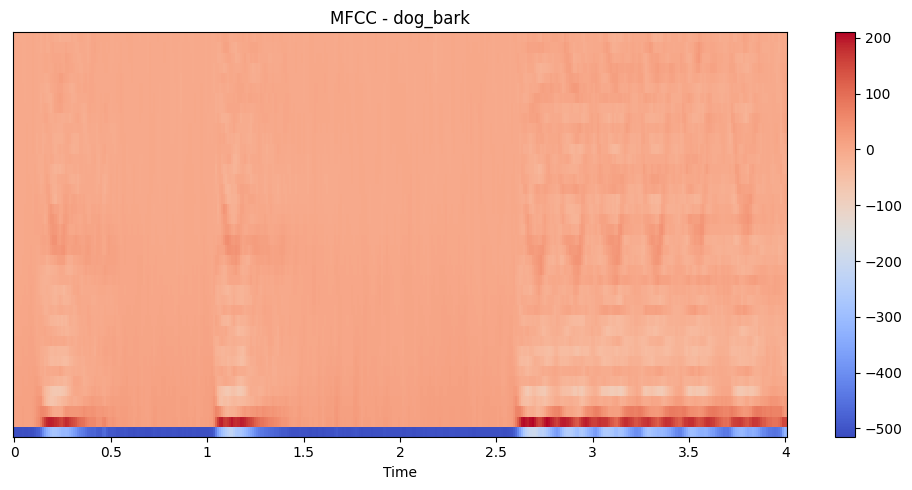

In [11]:
plt.figure(figsize=(10, 5))

librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sample_rate
)

plt.colorbar()

plt.title(
    f"MFCC - {audio_info['class'].iloc[0]}"
)

plt.tight_layout()
plt.show()

In [12]:
def extract_features(audio_path):

    audio, sr = librosa.load(audio_path, sr=22050)

    # MFCC
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    mfcc_features = np.mean(mfcc, axis=1)

    # Spectral Centroid
    spectral_centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr
    )

    centroid_mean = np.mean(spectral_centroid)

    # Spectral Bandwidth
    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=audio,
        sr=sr
    )

    bandwidth_mean = np.mean(spectral_bandwidth)

    # Spectral Rolloff
    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=audio,
        sr=sr
    )

    rolloff_mean = np.mean(spectral_rolloff)

    # Zero Crossing Rate
    zero_crossing = librosa.feature.zero_crossing_rate(
        audio
    )

    zero_crossing_mean = np.mean(zero_crossing)

    # Combine all features
    combined_features = np.concatenate([
        mfcc_features,
        [centroid_mean],
        [bandwidth_mean],
        [rolloff_mean],
        [zero_crossing_mean]
    ])

    return combined_features

In [13]:
# ==========================================
# 1. Build Feature Dataset
# ==========================================

from tqdm import tqdm
import numpy as np

features_combined = []
labels_combined = []

# Number of audio files selected from each sound class
MAX_FILES_PER_CLASS = 300

for sound_class in df["class"].unique():

    class_data = (
        df[df["class"] == sound_class]
        .head(MAX_FILES_PER_CLASS)
    )

    for _, row in tqdm(
        class_data.iterrows(),
        total=len(class_data),
        desc=f"Processing {sound_class}"
    ):

        audio_path = (
            f"../data/fold{row['fold']}/{row['slice_file_name']}"
        )

        try:
            feature_vector = extract_features(audio_path)

            features_combined.append(feature_vector)
            labels_combined.append(sound_class)

        except Exception as error:
            print(
                f"Error processing "
                f"{row['slice_file_name']}: {error}"
            )

# Convert lists to NumPy arrays
X = np.array(features_combined)
y = np.array(labels_combined)

print("Feature extraction completed!")
print("Feature matrix shape:", X.shape)
print("Label shape:", y.shape)

Processing car_horn:  26%|██▋       | 79/300 [00:01<00:04, 46.03it/s]C:\Users\Shruti\PycharmProjects\PythonProject6\.venv\lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1323
  warnings.warn(
Processing drilling: 100%|██████████| 300/300 [00:25<00:00, 11.58it/s]

Feature extraction completed!
Feature matrix shape: (3000, 44)
Label shape: (3000,)


In [14]:
# ==========================================
# 2. Encode Labels and Split Dataset
# ==========================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Convert sound class names into numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)
print("Number of classes:", len(label_encoder.classes_))
print("Classes:", label_encoder.classes_)

Training data: (2400, 44)
Testing data : (600, 44)
Number of classes: 10
Classes: ['air_conditioner' 'car_horn' 'children_playing' 'dog_bark' 'drilling'
 'engine_idling' 'gun_shot' 'jackhammer' 'siren' 'street_music']


In [15]:
# ==========================================
# 3. Train and Compare ML Models
# ==========================================

# ==========================================
# 3. Train and Compare ML Models
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# 1. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)


# 2. Standardized SVM
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", random_state=42))
])

svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_pred)


# 3. XGBoost
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_accuracy = accuracy_score(y_test, xgb_pred)


# Final comparison
print("========== MODEL COMPARISON ==========")
print(f"Random Forest : {rf_accuracy * 100:.2f}%")
print(f"SVM           : {svm_accuracy * 100:.2f}%")
print(f"XGBoost       : {xgb_accuracy * 100:.2f}%")

========== MODEL COMPARISON ==========
Random Forest : 94.17%
SVM           : 92.83%
XGBoost       : 92.83%


In [16]:
# ==========================================
# 4. RANDOM FOREST HYPERPARAMETER TUNING
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Parameters to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5]
}

# Create the model
rf_model_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

# Search for the best parameter combination
rf_tuned = GridSearchCV(
    estimator=rf_model_tuning,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Train and tune
rf_tuned.fit(X_train, y_train)

# Display results
print("\n========== RANDOM FOREST TUNING ==========")
print("Best Parameters:", rf_tuned.best_params_)
print(f"Best CV Accuracy: {rf_tuned.best_score_ * 100:.2f}%")

best_model = rf_tuned.best_estimator_

print("Best Random Forest model ready!")

Fitting 3 folds for each of 12 candidates, totalling 36 fits

========== RANDOM FOREST TUNING ==========
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 91.42%
Best Random Forest model ready!


In [18]:
# ==========================================
# 5. Final Model Evaluation
# ==========================================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict using the best tuned Random Forest
final_predictions = rf_tuned.predict(X_test)

# Calculate evaluation metrics
final_accuracy = accuracy_score(y_test, final_predictions)
final_precision = precision_score(
    y_test, final_predictions, average="macro"
)
final_recall = recall_score(
    y_test, final_predictions, average="macro"
)
final_f1 = f1_score(
    y_test, final_predictions, average="macro"
)

print("========== FINAL RANDOM FOREST RESULTS ==========")
print(f"Accuracy  : {final_accuracy * 100:.2f}%")
print(f"Precision : {final_precision * 100:.2f}%")
print(f"Recall    : {final_recall * 100:.2f}%")
print(f"F1 Score  : {final_f1 * 100:.2f}%")

========== FINAL RANDOM FOREST RESULTS ==========
Accuracy  : 94.17%
Precision : 94.26%
Recall    : 94.17%
F1 Score  : 94.14%


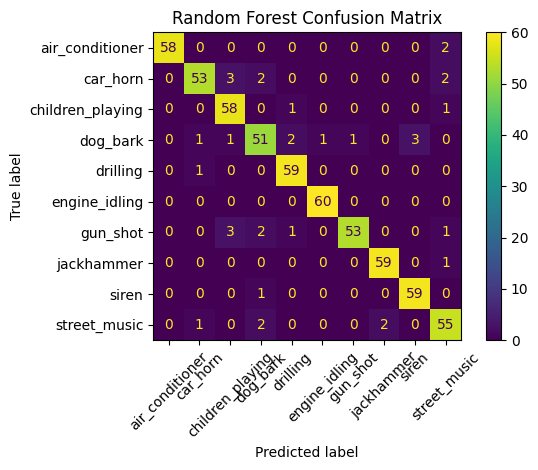


Top 10 Important Features:
               Feature  Importance
3               MFCC_4    0.051936
43  Zero_Crossing_Rate    0.049921
0               MFCC_1    0.044999
5               MFCC_6    0.039322
2               MFCC_3    0.036152
40   Spectral_Centroid    0.033793
42    Spectral_Rolloff    0.031861
6               MFCC_7    0.031660
39             MFCC_40    0.030833
7               MFCC_8    0.029271


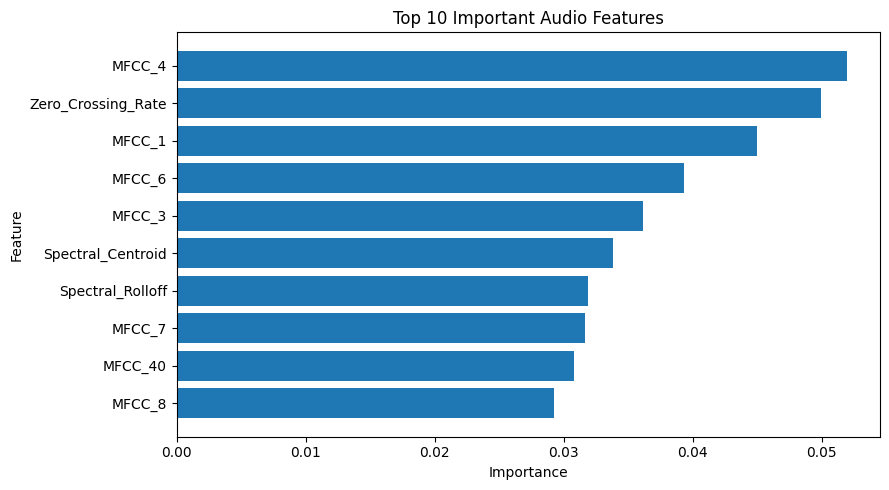

In [19]:
# ==========================================
# 6. Confusion Matrix and Feature Importance
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


# Feature Importance
importance = rf_tuned.best_estimator_.feature_importances_

feature_names = [
    f"MFCC_{i + 1}" for i in range(40)
] + [
    "Spectral_Centroid",
    "Spectral_Bandwidth",
    "Spectral_Rolloff",
    "Zero_Crossing_Rate"
]

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
)

print("\nTop 10 Important Features:")
print(feature_importance.head(10))

plt.figure(figsize=(9, 5))

top_features = feature_importance.head(10).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Audio Features")
plt.tight_layout()
plt.show()

Top 10 SHAP Features:
               Feature  Mean_SHAP
3               MFCC_4   0.020463
43  Zero_Crossing_Rate   0.014994
5               MFCC_6   0.014701
6               MFCC_7   0.010776
42    Spectral_Rolloff   0.010352
40   Spectral_Centroid   0.010201
0               MFCC_1   0.009926
7               MFCC_8   0.009127
2               MFCC_3   0.008200
41  Spectral_Bandwidth   0.007752


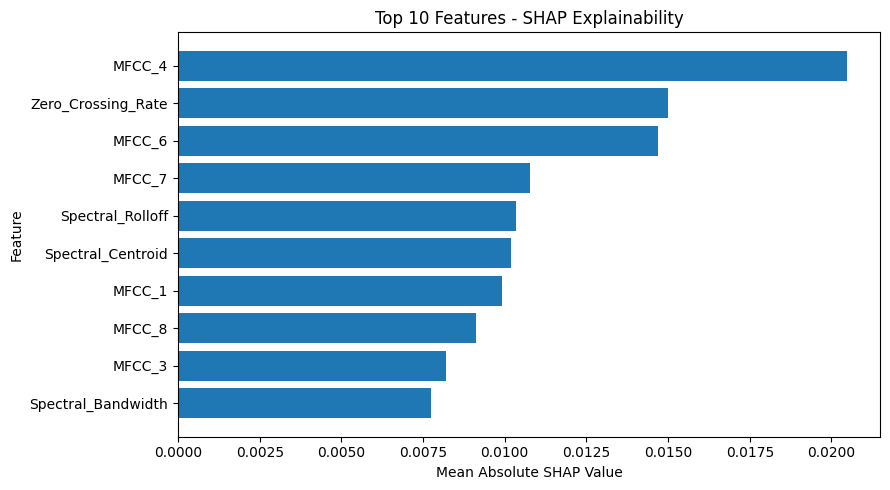


Final model saved successfully!

========== FINAL PREDICTION ==========
Audio File : ../data/fold1\101415-3-0-2.wav
Sound Class: dog_bark
Confidence : 63.50%


In [20]:
# ==========================================
# 7. Explainability + Final Model + Prediction
# ==========================================

import os
import joblib
import shap
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# A. SHAP Explainability
# ------------------------------------------

best_model = rf_tuned.best_estimator_

explainer = shap.TreeExplainer(best_model)

# Use a smaller sample for faster SHAP analysis
X_shap = X_test[:200]
shap_values = explainer.shap_values(X_shap)

# Handle multiclass SHAP output
if isinstance(shap_values, list):
    mean_shap = np.mean(
        np.abs(np.array(shap_values)),
        axis=(0, 1)
    )
else:
    shap_array = np.array(shap_values)

    if shap_array.ndim == 3:
        mean_shap = np.mean(
            np.abs(shap_array),
            axis=(0, 2)
        )
    else:
        mean_shap = np.mean(
            np.abs(shap_array),
            axis=0
        )

shap_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mean_SHAP": mean_shap
    })
    .sort_values("Mean_SHAP", ascending=False)
)

print("Top 10 SHAP Features:")
print(shap_importance.head(10))

top_shap = shap_importance.head(10).sort_values("Mean_SHAP")

plt.figure(figsize=(9, 5))
plt.barh(
    top_shap["Feature"],
    top_shap["Mean_SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 10 Features - SHAP Explainability")
plt.tight_layout()
plt.show()


# ------------------------------------------
# B. Save Final Model
# ------------------------------------------

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/final_noise_classifier.pkl"
)

joblib.dump(
    label_encoder,
    "../models/label_encoder.pkl"
)

print("\nFinal model saved successfully!")
# ==========================================
# NOISE SEVERITY CLASSIFICATION
# ==========================================

def classify_severity(db):
    if db < 50:
        return "Low"
    elif db < 70:
        return "Moderate"
    elif db < 85:
        return "High"
    else:
        return "Critical"


# ------------------------------------------
# C. Final Audio Prediction
# ------------------------------------------

sample_audio = audio_file

final_features = extract_features(sample_audio)
final_features = final_features.reshape(1, -1)

prediction = best_model.predict(final_features)
probabilities = best_model.predict_proba(final_features)

predicted_sound = label_encoder.inverse_transform(prediction)[0]
confidence = np.max(probabilities) * 100

print("\n========== FINAL PREDICTION ==========")
print("Audio File :", sample_audio)
print("Sound Class:", predicted_sound)
print(f"Confidence : {confidence:.2f}%")

In [21]:
import pandas as pd
import numpy as np

np.random.seed(42)

# Locations for our simulated IoT sensors
locations = [
    ("MG Road", 18.5204, 73.8567),
    ("Station Road", 18.5285, 73.8742),
    ("Market Area", 18.5158, 73.8570),
    ("College Road", 18.5308, 73.8475),
    ("Hospital Area", 18.5167, 73.8560),
    ("Residential Area", 18.5350, 73.8500)
]

sound_classes = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]

data = []

for location, latitude, longitude in locations:

    for reading in range(50):

        noise_db = np.random.randint(40, 101)

        sound = np.random.choice(sound_classes)

        confidence = np.random.uniform(60, 98)

        if noise_db < 50:
            severity = "Low"
        elif noise_db < 70:
            severity = "Moderate"
        elif noise_db < 85:
            severity = "High"
        else:
            severity = "Critical"

        data.append([
            location,
            latitude,
            longitude,
            reading,
            noise_db,
            sound,
            round(confidence, 2),
            severity
        ])

columns = [
    "Location",
    "Latitude",
    "Longitude",
    "Timestamp",
    "Noise_dB",
    "Sound_Class",
    "Confidence",
    "Severity"
]

df_iot = pd.DataFrame(data, columns=columns)

print("IoT dataset created successfully!")
print("Total readings:", len(df_iot))

df_iot.head()

IoT dataset created successfully!
Total readings: 300


,Location,Latitude,Longitude,Timestamp,Noise_dB,Sound_Class,Confidence,Severity
0,MG Road,18.5204,73.8567,0,78,dog_bark,96.13,High
1,MG Road,18.5204,73.8567,1,82,jackhammer,82.75,High
2,MG Road,18.5204,73.8567,2,78,street_music,65.93,High
3,MG Road,18.5204,73.8567,3,50,jackhammer,72.68,Moderate
4,MG Road,18.5204,73.8567,4,79,jackhammer,84.73,High


In [22]:
df_iot.to_csv(
    "../data/iot_noise_readings.csv",
    index=False
)

print("IoT data saved successfully!")

IoT data saved successfully!


In [23]:
# Calculate average noise for each location

hotspot_summary = df_iot.groupby("Location").agg(
    Average_Noise=("Noise_dB", "mean"),
    Maximum_Noise=("Noise_dB", "max"),
    High_Readings=("Noise_dB", lambda x: (x >= 70).sum()),
    Total_Readings=("Noise_dB", "count")
).reset_index()

hotspot_summary

,Location,Average_Noise,Maximum_Noise,High_Readings,Total_Readings
0,College Road,68.06,100,24,50
1,Hospital Area,69.32,98,22,50
2,MG Road,73.06,100,28,50
3,Market Area,71.86,100,24,50
4,Residential Area,71.10,100,28,50
5,Station Road,69.40,99,25,50


In [22]:
# ==========================================
# HOTSPOT ANALYSIS AND PRIORITY RANKING
# ==========================================

import pandas as pd
from pathlib import Path

# 1. Load the existing IoT readings
possible_paths = [
    Path("../data/iot_noise_readings.csv"),
    Path("data/iot_noise_readings.csv")
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if csv_path is None:
    raise FileNotFoundError(
        "iot_noise_readings.csv not found. "
        "Run the IoT dataset creation cell first."
    )

df_iot = pd.read_csv(csv_path)

print("IoT readings loaded:", len(df_iot))


# 2. Calculate statistics for each location
hotspot_summary = df_iot.groupby("Location").agg(
    Average_Noise=("Noise_dB", "mean"),
    Maximum_Noise=("Noise_dB", "max"),
    High_Readings=("Noise_dB", lambda x: (x >= 70).sum()),
    Total_Readings=("Noise_dB", "count")
).reset_index()


# 3. Calculate normalized project scores
hotspot_summary["Noise_Score"] = (
    hotspot_summary["Average_Noise"] / 100
)

hotspot_summary["Persistence_Score"] = (
    hotspot_summary["High_Readings"] /
    hotspot_summary["Total_Readings"]
)

hotspot_summary["Peak_Score"] = (
    hotspot_summary["Maximum_Noise"] / 100
)


# 4. Calculate the final hotspot score
hotspot_summary["Hotspot_Score"] = (
    0.50 * hotspot_summary["Noise_Score"]
    + 0.30 * hotspot_summary["Persistence_Score"]
    + 0.20 * hotspot_summary["Peak_Score"]
) * 100


# 5. Assign priority
def get_priority(score):
    if score >= 80:
        return "Critical"
    elif score >= 65:
        return "High"
    elif score >= 50:
        return "Moderate"
    else:
        return "Low"


hotspot_summary["Priority"] = (
    hotspot_summary["Hotspot_Score"].apply(get_priority)
)


# 6. Rank locations from highest to lowest score
hotspot_summary = hotspot_summary.sort_values(
    "Hotspot_Score",
    ascending=False
).reset_index(drop=True)


# 7. Display final results
print("\n========== URBAN NOISE HOTSPOTS ==========")

print(
    hotspot_summary[
        [
            "Location",
            "Average_Noise",
            "Maximum_Noise",
            "High_Readings",
            "Hotspot_Score",
            "Priority"
        ]
    ].round(2).to_string(index=False)
)

print("\nHotspot analysis completed successfully!")

IoT readings loaded: 300

========== URBAN NOISE HOTSPOTS ==========
        Location  Average_Noise  Maximum_Noise  High_Readings  Hotspot_Score Priority
         MG Road          73.06            100             28          73.33     High
Residential Area          71.10            100             28          72.35     High
     Market Area          71.86            100             24          70.33     High
    Station Road          69.40             99             25          69.50     High
    College Road          68.06            100             24          68.43     High
   Hospital Area          69.32             98             22          67.46     High

Hotspot analysis completed successfully!


In [23]:
def get_priority(score):

    if score >= 80:
        return "Critical"

    elif score >= 65:
        return "High"

    elif score >= 50:
        return "Moderate"

    else:
        return "Low"


hotspot_summary["Priority"] = (
    hotspot_summary["Hotspot_Score"]
    .apply(get_priority)
)

hotspot_summary[
    [
        "Location",
        "Hotspot_Score",
        "Priority",
        "Average_Noise",
        "Maximum_Noise",
        "High_Readings"
    ]
]

,Location,Hotspot_Score,Priority,Average_Noise,Maximum_Noise,High_Readings
0,MG Road,73.33,High,73.06,100,28
1,Residential Area,72.35,High,71.10,100,28
2,Market Area,70.33,High,71.86,100,24
3,Station Road,69.50,High,69.40,99,25
4,College Road,68.43,High,68.06,100,24
5,Hospital Area,67.46,High,69.32,98,22


In [24]:
# Time-based noise persistence analysis

df_iot["Time_Period"] = df_iot["Timestamp"] % 24

def get_time_period(hour):
    if hour < 6:
        return "Night"
    elif hour < 12:
        return "Morning"
    elif hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df_iot["Time_Period"] = df_iot["Time_Period"].apply(get_time_period)

time_summary = df_iot.groupby(
    ["Location", "Time_Period"]
).agg(
    Average_Noise=("Noise_dB", "mean"),
    Maximum_Noise=("Noise_dB", "max"),
    High_Readings=("Noise_dB", lambda x: (x >= 70).sum()),
    Total_Readings=("Noise_dB", "count")
).reset_index()

time_summary["Persistence"] = (
    time_summary["High_Readings"] /
    time_summary["Total_Readings"]
) * 100

time_summary

,Location,Time_Period,Average_Noise,Maximum_Noise,High_Readings,Total_Readings,Persistence
0,College Road,Afternoon,65.166667,97,4,12,33.333333
1,College Road,Evening,69.500000,94,8,12,66.666667
2,College Road,Morning,66.416667,92,4,12,33.333333
3,College Road,Night,70.714286,100,8,14,57.142857
4,Hospital Area,Afternoon,73.500000,98,6,12,50.000000
5,Hospital Area,Evening,73.250000,95,7,12,58.333333
6,Hospital Area,Morning,71.583333,96,5,12,41.666667
7,Hospital Area,Night,60.428571,88,4,14,28.571429
8,MG Road,Afternoon,74.666667,99,7,12,58.333333
9,MG Road,Evening,66.416667,100,5,12,41.666667


In [25]:
!pip install folium


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import folium
import pandas as pd

# Load IoT noise readings dataset
iot_df = pd.read_csv('../data/iot_noise_readings.csv')
iot_df.columns = iot_df.columns.str.strip()

# Detect latitude and longitude columns
lat_col = [c for c in iot_df.columns if 'lat' in c.lower()][0]
lon_col = [c for c in iot_df.columns if 'lon' in c.lower()][0]

# Akurdi, Pimpri-Chinchwad coordinates
akurdi_coords = [18.523, 73.858]

# Create Folium map centered on Akurdi
m = folium.Map(location=akurdi_coords, zoom_start=13)

# Add marker for Akurdi Monitoring Station
folium.Marker(
    location=akurdi_coords,
    popup="<b>Akurdi Noise Monitoring Station</b>",
    tooltip="Akurdi Station",
    icon=folium.Icon(color="red", icon="info-sign")
).add_to(m)

# Add remaining sensor points from your dataset
for _, row in iot_df.iterrows():
    loc_name = row.get('Location', row.get('location', 'Sensor Point'))
    folium.Marker(
        location=[row[lat_col], row[lon_col]],
        popup=f"Location: {loc_name}",
        tooltip=str(loc_name)
    ).add_to(m)

m

In [28]:
from folium.plugins import HeatMap

# Prepare heatmap data
heat_data = []

for _, row in iot_df.iterrows():
    heat_data.append([
        row[lat_col],
        row[lon_col],
        row["Noise_dB"]
    ])

# Add heatmap
HeatMap(
    heat_data,
    radius=25,
    blur=20,
    max_zoom=14
).add_to(m)

m

In [29]:
m.save("../data/noise_hotspot_map.html")

print("Noise hotspot map saved successfully!")

Noise hotspot map saved successfully!


In [30]:
import matplotlib.pyplot as plt

# Calculate important statistics
total_readings = len(iot_df)
average_noise = iot_df["Noise_dB"].mean()
maximum_noise = iot_df["Noise_dB"].max()
critical_count = (iot_df["Severity"] == "Critical").sum()
high_count = (iot_df["Severity"] == "High").sum()

print("====================================")
print("   SMART NOISE MONITORING DASHBOARD")
print("====================================")
print(f"Total Sensor Readings : {total_readings}")
print(f"Average Noise Level   : {average_noise:.2f} dB")
print(f"Maximum Noise Level   : {maximum_noise:.2f} dB")
print(f"High Noise Readings   : {high_count}")
print(f"Critical Readings     : {critical_count}")
print("====================================")

   SMART NOISE MONITORING DASHBOARD
Total Sensor Readings : 300
Average Noise Level   : 70.47 dB
Maximum Noise Level   : 100.00 dB
High Noise Readings   : 67
Critical Readings     : 84


In [31]:
# Display top noise hotspots

dashboard_hotspots = hotspot_summary[
    [
        "Location",
        "Hotspot_Score",
        "Priority",
        "Average_Noise",
        "Maximum_Noise"
    ]
].copy()

dashboard_hotspots = dashboard_hotspots.sort_values(
    "Hotspot_Score",
    ascending=False
)

dashboard_hotspots

,Location,Hotspot_Score,Priority,Average_Noise,Maximum_Noise
0,MG Road,73.33,High,73.06,100
1,Residential Area,72.35,High,71.10,100
2,Market Area,70.33,High,71.86,100
3,Station Road,69.50,High,69.40,99
4,College Road,68.43,High,68.06,100
5,Hospital Area,67.46,High,69.32,98


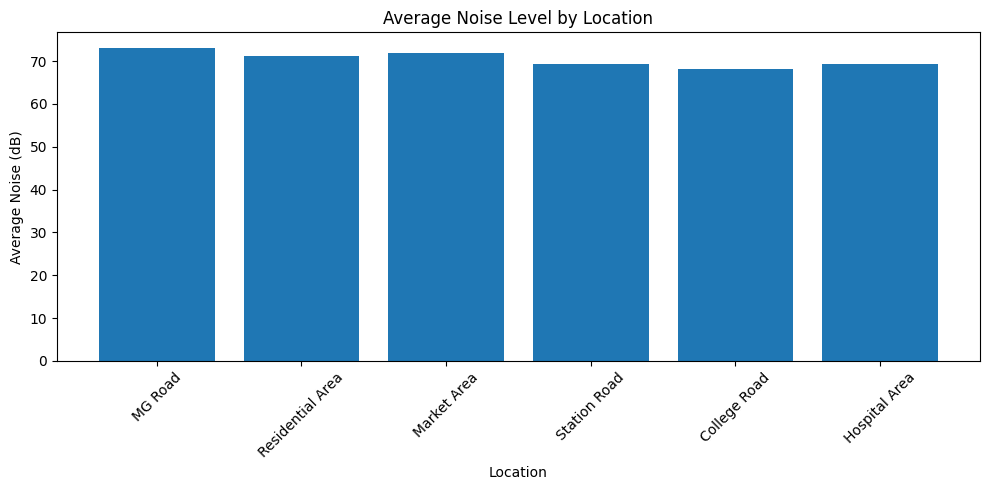

In [32]:
plt.figure(figsize=(10, 5))

plt.bar(
    dashboard_hotspots["Location"],
    dashboard_hotspots["Average_Noise"]
)

plt.xlabel("Location")
plt.ylabel("Average Noise (dB)")
plt.title("Average Noise Level by Location")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# ==========================================
# FINAL AUDIO PREDICTION
# ==========================================

best_model = rf_tuned.best_estimator_

sample_audio = audio_file

# Extract the same 44 features used during training
final_features = extract_features(sample_audio).reshape(1, -1)

# Predict sound class
prediction = best_model.predict(final_features)
probabilities = best_model.predict_proba(final_features)

# Convert prediction to sound name
predicted_class = label_encoder.inverse_transform(prediction)[0]

# Model confidence
confidence = np.max(probabilities) * 100

# Enter measured noise level
db = float(input("Enter noise level (dB): "))

# Classify severity
severity = classify_severity(db)

# Recommendation
if severity == "Low":
    recommendation = "Noise level is low. No immediate action required."
elif severity == "Moderate":
    recommendation = "Monitor the noise level and reduce unnecessary noise."
elif severity == "High":
    recommendation = "High noise detected. Reduce the noise source."
else:
    recommendation = "Critical noise level. Immediate action is recommended."

print("\n========== FINAL PREDICTION ==========")
print("Detected Sound :", predicted_class)
print(f"Confidence     : {confidence:.2f}%")
print(f"Noise Level    : {db:.1f} dB")
print("Severity       :", severity)
print("Recommendation :", recommendation)


========== FINAL PREDICTION ==========
Detected Sound : dog_bark
Confidence     : 63.50%
Noise Level    : 85.0 dB
Severity       : Critical
Recommendation : Critical noise level. Immediate action is recommended.


In [34]:
# Final Smart Noise Monitoring System Summary

print("=" * 55)
print("       SMART URBAN NOISE MONITORING SYSTEM")
print("=" * 55)

print("\n1. AUDIO ANALYSIS")
print("Detected Sound Class :", predicted_class)
print(f"ML Confidence        : {confidence:.2f}%")

print("\n2. NOISE ANALYSIS")
print(f"Noise Level          : {db:.1f} dB")
print("Severity             :", severity)

print("\n3. HOTSPOT ANALYSIS")

top = hotspot_summary.iloc[0]

print("Top Priority Location:", top["Location"])
print(f"Hotspot Score        : {top['Hotspot_Score']:.2f}")
print("Priority             :", top["Priority"])
print(f"Average Noise        : {top['Average_Noise']:.2f} dB")
print(f"Maximum Noise        : {top['Maximum_Noise']:.2f} dB")

print("\n4. SYSTEM RECOMMENDATION")
print(recommendation)

print("\n" + "=" * 55)
print("          SYSTEM ANALYSIS COMPLETED")
print("=" * 55)

       SMART URBAN NOISE MONITORING SYSTEM

1. AUDIO ANALYSIS
Detected Sound Class : dog_bark
ML Confidence        : 63.50%

2. NOISE ANALYSIS
Noise Level          : 85.0 dB
Severity             : Critical

3. HOTSPOT ANALYSIS
Top Priority Location: MG Road
Hotspot Score        : 73.33
Priority             : High
Average Noise        : 73.06 dB
Maximum Noise        : 100.00 dB

4. SYSTEM RECOMMENDATION
Critical noise level. Immediate action is recommended.

          SYSTEM ANALYSIS COMPLETED


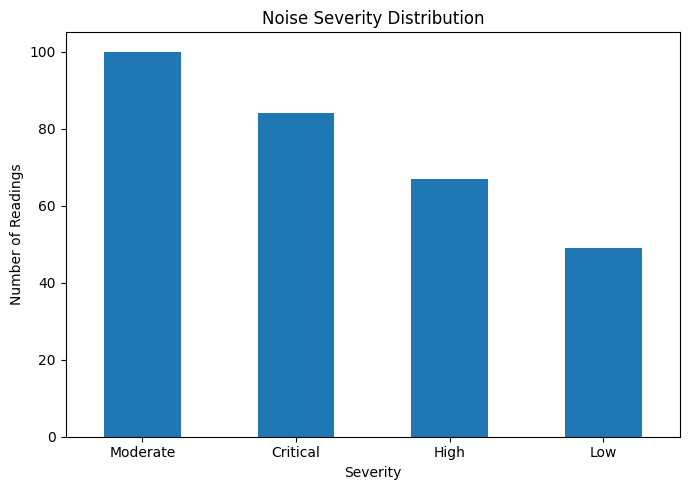

In [35]:
import matplotlib.pyplot as plt

# 1. Noise severity distribution
severity_counts = iot_df["Severity"].value_counts()

plt.figure(figsize=(7, 5))
severity_counts.plot(kind="bar")

plt.title("Noise Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of Readings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

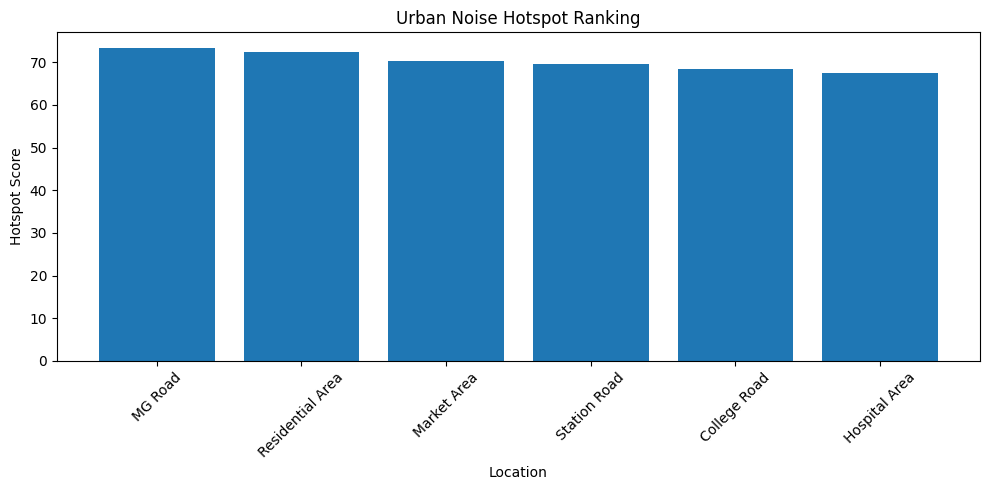

In [36]:
# 2. Hotspot ranking

plt.figure(figsize=(10, 5))

plt.bar(
    hotspot_summary["Location"],
    hotspot_summary["Hotspot_Score"]
)

plt.title("Urban Noise Hotspot Ranking")
plt.xlabel("Location")
plt.ylabel("Hotspot Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

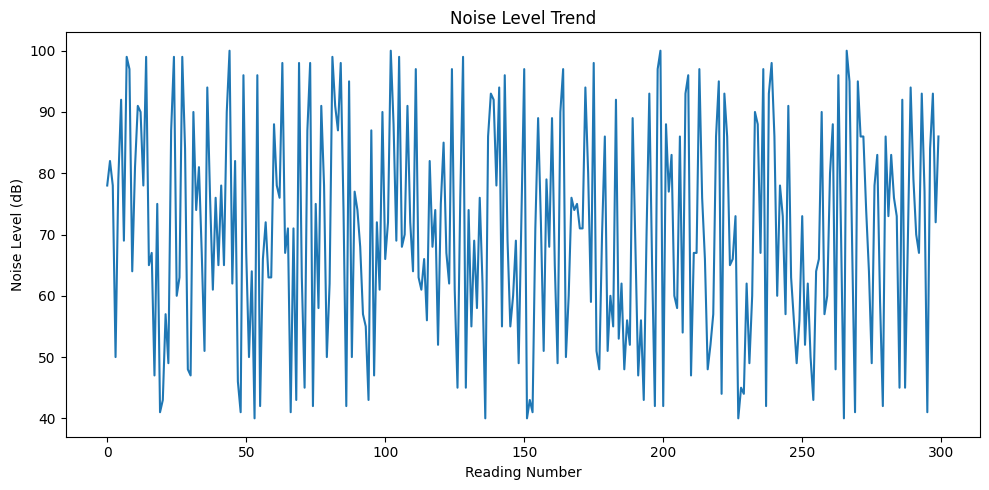

In [37]:
# 3. Noise trend over sensor readings

plt.figure(figsize=(10, 5))

plt.plot(iot_df["Noise_dB"])

plt.title("Noise Level Trend")
plt.xlabel("Reading Number")
plt.ylabel("Noise Level (dB)")

plt.tight_layout()
plt.show()

In [38]:
hotspot_summary[
    [
        "Location",
        "Average_Noise",
        "Maximum_Noise",
        "High_Readings",
        "Hotspot_Score",
        "Priority"
    ]
]

,Location,Average_Noise,Maximum_Noise,High_Readings,Hotspot_Score,Priority
0,MG Road,73.06,100,28,73.33,High
1,Residential Area,71.10,100,28,72.35,High
2,Market Area,71.86,100,24,70.33,High
3,Station Road,69.40,99,25,69.50,High
4,College Road,68.06,100,24,68.43,High
5,Hospital Area,69.32,98,22,67.46,High


In [39]:
m

In [40]:
# ==========================================
# IMPROVED ANN - COMPLETE TRAINING CODE
# ==========================================

import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Split training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# 2. Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_fit)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

# 3. Build the ANN model
ann_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.20),

    Dense(32, activation="relu"),

    Dense(
        len(label_encoder.classes_),
        activation="softmax"
    )
])

# 4. Compile the model
ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Stop training when validation stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# 6. Train the ANN
history_ann = ann_model.fit(
    X_train_scaled,
    y_fit,
    validation_data=(X_val_scaled, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# 7. Evaluate on the untouched test set
ann_loss, ann_accuracy = ann_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("\n========== ANN FINAL RESULTS ==========")
print(f"ANN Test Accuracy: {ann_accuracy * 100:.2f}%")

Training shape: (2040, 44)
Validation shape: (360, 44)
Testing shape: (600, 44)
Epoch 1/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.2417 - loss: 2.1803 - val_accuracy: 0.4167 - val_loss: 1.9624 - learning_rate: 5.0000e-04
Epoch 2/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4451 - loss: 1.6315 - val_accuracy: 0.5889 - val_loss: 1.6420 - learning_rate: 5.0000e-04
Epoch 3/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5466 - loss: 1.3749 - val_accuracy: 0.6806 - val_loss: 1.3281 - learning_rate: 5.0000e-04
Epoch 4/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6270 - loss: 1.1866 - val_accuracy: 0.7472 - val_loss: 1.0544 - learning_rate: 5.0000e-04
Epoch 5/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6696 - loss: 1.0273 - val_accuracy: 0.7611 - val_loss: 0.8618 - learning_rate: 5.0000e-04
Epoch 6/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7162 - loss: 0.9163 - val_accuracy: 0.8028 - val_loss: 0.7292 - learning_rate: 5.0000e

In [42]:
ann_loss, ann_accuracy = ann_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("ANN Test Accuracy:",
      f"{ann_accuracy * 100:.2f}%")

ANN Test Accuracy: 92.67%


In [43]:
# ==========================================
# STEP 4: SAVE AUDIO PREDICTION HISTORY
# ==========================================

from datetime import datetime
from pathlib import Path
import pandas as pd

# File for storing prediction history
events_file = ROOT / "data" / "audio_prediction_events.csv"
events_file.parent.mkdir(parents=True, exist_ok=True)

# Create one record from your actual model prediction
new_event = pd.DataFrame([{
    "Timestamp": datetime.now().isoformat(timespec="seconds"),
    "Audio_File": Path(sample_audio).name,
    "Predicted_Sound": predicted_class,
    "Model_Probability_Percent": round(confidence, 2),
    "Location": "Not recorded",
    "Noise_Level_dB_SPL": None,
    "Data_Type": "Audio classification"
}])

# Append the record without deleting previous records
if events_file.exists():
    new_event.to_csv(
        events_file,
        mode="a",
        header=False,
        index=False
    )
else:
    new_event.to_csv(
        events_file,
        index=False
    )

print("Prediction saved successfully!")
print(new_event.to_string(index=False))
print("\nSaved at:", events_file)

Prediction saved successfully!
          Timestamp       Audio_File Predicted_Sound  Model_Probability_Percent     Location Noise_Level_dB_SPL            Data_Type
2026-10-20T00:11:41 101415-3-0-2.wav        dog_bark                       63.5 Not recorded               None Audio classification

Saved at: C:\Users\Shruti\PycharmProjects\PythonProject6\data\audio_prediction_events.csv


===== SMART NOISE MONITORING: EVENT HISTORY =====
Total audio analyses: 2

Recent predictions:


,Timestamp,Audio_File,Predicted_Sound,Model_Probability_Percent,Location,Noise_Level_dB_SPL,Data_Type
0,2026-10-14T02:10:32,101415-3-0-2.wav,dog_bark,63.5,Not recorded,NaN,Audio classification
1,2026-10-20T00:11:41,101415-3-0-2.wav,dog_bark,63.5,Not recorded,NaN,Audio classification



Sound classes detected:
Predicted_Sound
dog_bark    2
Name: count, dtype: int64


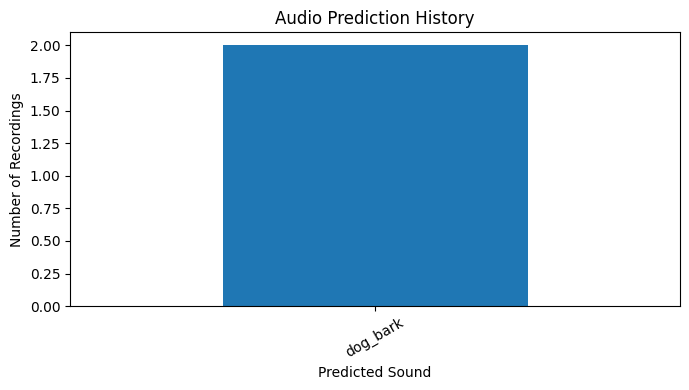

In [44]:
# ==========================================
# STEP 5: AUDIO EVENT HISTORY DASHBOARD
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

events_file = ROOT / "data" / "audio_prediction_events.csv"

events_df = pd.read_csv(events_file)

print("===== SMART NOISE MONITORING: EVENT HISTORY =====")
print("Total audio analyses:", len(events_df))

print("\nRecent predictions:")
display(events_df.tail(10))

print("\nSound classes detected:")
print(events_df["Predicted_Sound"].value_counts())

# Plot detected sound classes
events_df["Predicted_Sound"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Audio Prediction History"
)

plt.xlabel("Predicted Sound")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

     SMART URBAN NOISE MONITORING SYSTEM

ACTUAL AUDIO CLASSIFICATION RECORDS
Total analyses: 2


,Timestamp,Audio_File,Predicted_Sound,Model_Probability_Percent,Location,Noise_Level_dB_SPL,Data_Type
0,2026-10-14T02:10:32,101415-3-0-2.wav,dog_bark,63.5,Not recorded,NaN,Audio classification
1,2026-10-20T00:11:41,101415-3-0-2.wav,dog_bark,63.5,Not recorded,NaN,Audio classification



Most frequently predicted sound classes:


,Sound Class,Number of Predictions
0,dog_bark,2



SIMULATED MULTI-LOCATION HOTSPOT RESULTS


,Location,Average_Noise,Maximum_Noise,High_Readings,Hotspot_Score,Priority
0,MG Road,73.06,100,28,73.33,High
1,Residential Area,71.10,100,28,72.35,High
2,Market Area,71.86,100,24,70.33,High
3,Station Road,69.40,99,25,69.50,High
4,College Road,68.06,100,24,68.43,High
5,Hospital Area,69.32,98,22,67.46,High


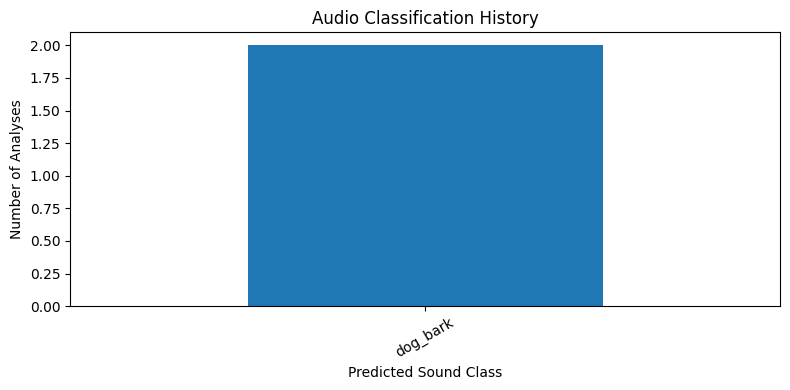

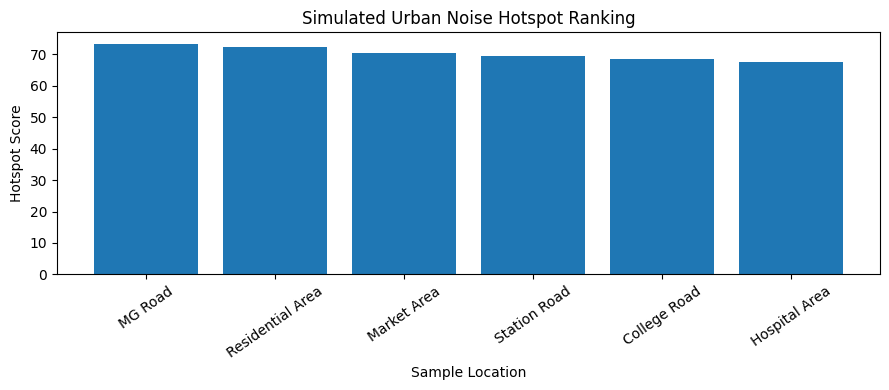


Dashboard analysis completed.


In [45]:
# ==========================================
# STEP 5: INTEGRATED NOISE MONITORING DASHBOARD
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Load saved records
events_path = ROOT / "data" / "audio_prediction_events.csv"
iot_path = ROOT / "data" / "iot_noise_readings.csv"

if not events_path.exists():
    raise FileNotFoundError("Audio prediction history not found.")

if not iot_path.exists():
    raise FileNotFoundError("IoT sample data not found.")

events_df = pd.read_csv(events_path)
iot_df = pd.read_csv(iot_path)

# 2. Show actual audio-classification history
print("=" * 55)
print("     SMART URBAN NOISE MONITORING SYSTEM")
print("=" * 55)

print("\nACTUAL AUDIO CLASSIFICATION RECORDS")
print("Total analyses:", len(events_df))

display(events_df.tail(10))

print("\nMost frequently predicted sound classes:")
display(
    events_df["Predicted_Sound"]
    .value_counts()
    .rename_axis("Sound Class")
    .reset_index(name="Number of Predictions")
)

# 3. Calculate hotspot statistics from SIMULATED IoT readings
hotspot_summary = iot_df.groupby("Location").agg(
    Average_Noise=("Noise_dB", "mean"),
    Maximum_Noise=("Noise_dB", "max"),
    High_Readings=("Noise_dB", lambda x: (x >= 70).sum()),
    Total_Readings=("Noise_dB", "count"),
    Latitude=("Latitude", "first"),
    Longitude=("Longitude", "first")
).reset_index()

hotspot_summary["Noise_Score"] = (
    hotspot_summary["Average_Noise"] / 100
)

hotspot_summary["Persistence_Score"] = (
    hotspot_summary["High_Readings"]
    / hotspot_summary["Total_Readings"]
)

hotspot_summary["Peak_Score"] = (
    hotspot_summary["Maximum_Noise"] / 100
)

hotspot_summary["Hotspot_Score"] = 100 * (
    0.50 * hotspot_summary["Noise_Score"]
    + 0.30 * hotspot_summary["Persistence_Score"]
    + 0.20 * hotspot_summary["Peak_Score"]
)

def get_priority(score):
    if score >= 80:
        return "Critical"
    elif score >= 65:
        return "High"
    elif score >= 50:
        return "Moderate"
    return "Low"

hotspot_summary["Priority"] = (
    hotspot_summary["Hotspot_Score"].apply(get_priority)
)

hotspot_summary = hotspot_summary.sort_values(
    "Hotspot_Score", ascending=False
).reset_index(drop=True)

print("\nSIMULATED MULTI-LOCATION HOTSPOT RESULTS")
display(
    hotspot_summary[
        [
            "Location",
            "Average_Noise",
            "Maximum_Noise",
            "High_Readings",
            "Hotspot_Score",
            "Priority"
        ]
    ].round(2)
)

# 4. Plot actual audio prediction history
plt.figure(figsize=(8, 4))

events_df["Predicted_Sound"].value_counts().plot(kind="bar")

plt.title("Audio Classification History")
plt.xlabel("Predicted Sound Class")
plt.ylabel("Number of Analyses")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 5. Plot simulated hotspot rankings
plt.figure(figsize=(9, 4))

plt.bar(
    hotspot_summary["Location"],
    hotspot_summary["Hotspot_Score"]
)

plt.title("Simulated Urban Noise Hotspot Ranking")
plt.xlabel("Sample Location")
plt.ylabel("Hotspot Score")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("\nDashboard analysis completed.")

In [46]:
# ==========================================
# STEP 5B: GIS HOTSPOT MAP
# ==========================================

import folium
from folium.plugins import HeatMap
from IPython.display import display

# Center the map on the sample locations
map_center = [
    hotspot_summary["Latitude"].mean(),
    hotspot_summary["Longitude"].mean()
]

m = folium.Map(
    location=map_center,
    zoom_start=13
)

# Add one marker per sample location
for _, row in hotspot_summary.iterrows():

    popup_text = (
        f"Location: {row['Location']}<br>"
        f"Average noise: {row['Average_Noise']:.1f} dB "
        f"(simulated)<br>"
        f"Hotspot score: {row['Hotspot_Score']:.2f}<br>"
        f"Priority: {row['Priority']}"
    )

    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=row["Location"]
    ).add_to(m)

# Show relative simulated intensity
heat_data = [
    [row["Latitude"], row["Longitude"], row["Average_Noise"]]
    for _, row in hotspot_summary.iterrows()
]

HeatMap(
    heat_data,
    radius=25,
    blur=20
).add_to(m)

# Save the map
map_path = ROOT / "data" / "noise_hotspot_map.html"
m.save(str(map_path))

display(m)

print("GIS map saved to:", map_path)

GIS map saved to: C:\Users\Shruti\PycharmProjects\PythonProject6\data\noise_hotspot_map.html


In [47]:
# ==========================================
# STEP 6: FINAL PROJECT VERIFICATION
# ==========================================

from pathlib import Path
import pandas as pd

print("=" * 55)
print("     SMART URBAN NOISE MONITORING SYSTEM")
print("             FINAL SYSTEM CHECK")
print("=" * 55)

# 1. Check saved ML models
model_files = [
    ROOT / "models" / "final_noise_classifier.pkl",
    ROOT / "models" / "label_encoder.pkl"
]

print("\n1. MACHINE LEARNING MODELS")

for file in model_files:
    status = "READY" if file.exists() else "MISSING"
    print(f"{file.name}: {status}")

# 2. Check actual audio-prediction history
events_file = ROOT / "data" / "audio_prediction_events.csv"

print("\n2. AUDIO CLASSIFICATION HISTORY")

if events_file.exists():
    events = pd.read_csv(events_file)
    print("Saved predictions:", len(events))

    if not events.empty:
        latest = events.iloc[-1]
        print("Latest sound:", latest["Predicted_Sound"])
        print(
            "Model probability:",
            f"{latest['Model_Probability_Percent']:.2f}%"
        )
else:
    print("No saved audio predictions found.")

# 3. Check simulated IoT readings
iot_file = ROOT / "data" / "iot_noise_readings.csv"

print("\n3. SIMULATED IOT DATA")

if iot_file.exists():
    iot = pd.read_csv(iot_file)
    print("Sample readings:", len(iot))
    print("Sample locations:", iot["Location"].nunique())
    print("Data status: SIMULATED")
else:
    print("IoT sample file not found.")

# 4. Check GIS map
map_file = ROOT / "data" / "noise_hotspot_map.html"

print("\n4. GIS VISUALIZATION")

if map_file.exists():
    print("GIS map: READY")
    print("Map file:", map_file)
else:
    print("GIS map not found. Run the GIS map cell first.")

print("\n" + "=" * 55)
print("              VERIFICATION FINISHED")
print("=" * 55)

     SMART URBAN NOISE MONITORING SYSTEM
             FINAL SYSTEM CHECK

1. MACHINE LEARNING MODELS
final_noise_classifier.pkl: READY
label_encoder.pkl: READY

2. AUDIO CLASSIFICATION HISTORY
Saved predictions: 2
Latest sound: dog_bark
Model probability: 63.50%

3. SIMULATED IOT DATA
Sample readings: 300
Sample locations: 6
Data status: SIMULATED

4. GIS VISUALIZATION
GIS map: READY
Map file: C:\Users\Shruti\PycharmProjects\PythonProject6\data\noise_hotspot_map.html

              VERIFICATION FINISHED


In [65]:

# ==========================================
# STEP 2: BATCH PREDICTION FOR AKURDI AUDIO
# ==========================================

from pathlib import Path
import subprocess
import joblib
import librosa
import imageio_ffmpeg
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Locate the project folder
possible_roots = [Path.cwd(), *Path.cwd().parents]

ROOT = next(
    (
        p for p in possible_roots
        if (p / "models" / "final_noise_classifier.pkl").exists()
        and (p / "data" / "akurdi_recordings").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find the project folder containing "
        "models/final_noise_classifier.pkl and data/akurdi_recordings."
    )

RECORDING_DIR = ROOT / "data" / "akurdi_recordings"
CONVERTED_DIR = RECORDING_DIR / "converted"
OUTPUT_FILE = ROOT / "data" / "akurdi_batch_predictions.csv"

CONVERTED_DIR.mkdir(parents=True, exist_ok=True)

# 2. Find CURRENT recordings only.
# Do not read older files from the converted subfolder.
supported_extensions = {
    ".wav", ".mp3", ".mp4", ".m4a",
    ".flac", ".ogg", ".aac", ".wma", ".mov"
}

audio_files = sorted(
    [
        p for p in RECORDING_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in supported_extensions
    ],
    key=lambda p: p.name.lower()
)

print("Project folder:", ROOT)
print("Current recordings found:", len(audio_files))

for file in audio_files:
    print(" -", file.name)

if not audio_files:
    raise FileNotFoundError(
        f"No supported audio/video files found directly inside "
        f"{RECORDING_DIR}"
    )

# 3. Load the saved model and label encoder
model = joblib.load(
    ROOT / "models" / "final_noise_classifier.pkl"
)

label_encoder = joblib.load(
    ROOT / "models" / "label_encoder.pkl"
)

# Obtain the bundled FFmpeg executable
ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()


# 4. Convert each source file to standard WAV format
def convert_to_standard_wav(source_file):
    converted_file = (
        CONVERTED_DIR / f"{source_file.stem}_converted.wav"
    )

    command = [
        ffmpeg_exe,
        "-hide_banner",
        "-loglevel", "error",
        "-y",
        "-i", str(source_file),
        "-vn",
        "-ac", "1",
        "-ar", "22050",
        "-c:a", "pcm_s16le",
        str(converted_file)
    ]

    subprocess.run(
        command,
        check=True,
        capture_output=True,
        text=True
    )

    if not converted_file.exists() or converted_file.stat().st_size == 0:
        raise ValueError("FFmpeg did not create a valid WAV file.")

    return converted_file


# 5. Extract the same 44 features used by the trained model
def extract_44_features(audio_path):
    audio, sr = librosa.load(
        str(audio_path),
        sr=22050,
        mono=True
    )

    if len(audio) == 0:
        raise ValueError("Audio file is empty.")

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    mfcc_features = np.mean(mfcc, axis=1)

    centroid = np.mean(
        librosa.feature.spectral_centroid(
            y=audio, sr=sr
        )
    )

    bandwidth = np.mean(
        librosa.feature.spectral_bandwidth(
            y=audio, sr=sr
        )
    )

    rolloff = np.mean(
        librosa.feature.spectral_rolloff(
            y=audio, sr=sr
        )
    )

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(y=audio)
    )

    features = np.concatenate([
        mfcc_features,
        [centroid, bandwidth, rolloff, zcr]
    ])

    if len(features) != 44:
        raise ValueError(
            f"Expected 44 features but extracted {len(features)}."
        )

    return features


# 6. Predict the sounds in the current recordings
records = []
failed_files = []

print("\nStarting audio conversion and prediction...\n")

for source_file in audio_files:
    try:
        # Convert the source, even if it has a .wav extension,
        # so the model receives a standardized audio file.
        standardized_file = convert_to_standard_wav(source_file)

        features = extract_44_features(standardized_file)
        X_audio = features.reshape(1, -1)

        raw_prediction = model.predict(X_audio)[0]

        # Support models trained on encoded labels or string labels.
        try:
            predicted_sound = label_encoder.inverse_transform(
                [int(raw_prediction)]
            )[0]
        except (ValueError, TypeError):
            predicted_sound = str(raw_prediction)

        predicted_sound = str(predicted_sound)

        # Classifier confidence estimate, if available.
        probability_percent = np.nan

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_audio)[0]
            probability_percent = round(
                float(np.max(probabilities)) * 100, 2
            )

        # Preserve the ORIGINAL filename so the hotspot cell
        # can match it to the correct location.
        records.append({
            "Audio_File": source_file.name,
            "Predicted_Sound": predicted_sound,
            "Model_Probability_Percent": probability_percent,
            "Location": "Assign in hotspot mapping",
            "Data_Type": "Audio-file model prediction"
        })

        confidence_text = (
            f"{probability_percent:.2f}%"
            if pd.notna(probability_percent)
            else "Not available"
        )

        print(
            f"{source_file.name} -> "
            f"{predicted_sound} "
            f"(model confidence estimate: {confidence_text})"
        )

    except Exception as error:
        failed_files.append({
            "Audio_File": source_file.name,
            "Error": str(error)
        })

        print(f"ERROR: {source_file.name}: {error}")


# 7. Save the NEW prediction CSV
if records:
    results_df = pd.DataFrame(records)

    results_df.to_csv(
        OUTPUT_FILE,
        index=False
    )

    print("\n========== NEW BATCH RESULTS ==========")
    display(results_df)

    print("\nNew predictions saved to:")
    print(OUTPUT_FILE)

else:
    raise RuntimeError(
        "No recordings were processed successfully. "
        "Check the conversion errors above. "
        "The old prediction CSV has not been updated by this run."
    )

if failed_files:
    print("\n========== FILES THAT FAILED ==========")
    display(pd.DataFrame(failed_files))
else:
    print("\nAll current recordings were processed successfully.")


Project folder: C:\Users\Shruti\PycharmProjects\PythonProject6
Current recordings found: 5
 - dharamaraj_chowk.wav
 - dy_patil_road.wav
 - garden.wav
 - gurudwara.wav
 - pradhikaran.wav

Starting audio conversion and prediction...

dharamaraj_chowk.wav -> children_playing (model confidence estimate: 28.00%)
dy_patil_road.wav -> siren (model confidence estimate: 25.50%)
garden.wav -> children_playing (model confidence estimate: 25.50%)
gurudwara.wav -> siren (model confidence estimate: 25.00%)
pradhikaran.wav -> dog_bark (model confidence estimate: 27.00%)

========== NEW BATCH RESULTS ==========


,Audio_File,Predicted_Sound,Model_Probability_Percent,Location,Data_Type
0,dharamaraj_chowk.wav,children_playing,28.0,Assign in hotspot mapping,Audio-file model prediction
1,dy_patil_road.wav,siren,25.5,Assign in hotspot mapping,Audio-file model prediction
2,garden.wav,children_playing,25.5,Assign in hotspot mapping,Audio-file model prediction
3,gurudwara.wav,siren,25.0,Assign in hotspot mapping,Audio-file model prediction
4,pradhikaran.wav,dog_bark,27.0,Assign in hotspot mapping,Audio-file model prediction



New predictions saved to:
C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_batch_predictions.csv

All current recordings were processed successfully.


In [66]:
# ==========================================
# FIX: CONVERT RECORDINGS TO STANDARD WAV
# ==========================================

from pathlib import Path
import subprocess
import imageio_ffmpeg

recording_dir = ROOT / "data" / "akurdi_recordings"
converted_dir = recording_dir / "converted"
converted_dir.mkdir(exist_ok=True)

ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

supported_formats = {".wav", ".mp3", ".m4a", ".mp4"}

for source in sorted(recording_dir.iterdir()):

    if not source.is_file():
        continue

    if source.suffix.lower() not in supported_formats:
        continue

    output = converted_dir / f"{source.stem}_converted.wav"

    print("\nConverting:", source.name)

    command = [
        ffmpeg,
        "-y",
        "-hide_banner",
        "-loglevel", "error",
        "-i", str(source),
        "-vn",
        "-ac", "1",
        "-ar", "22050",
        "-c:a", "pcm_s16le",
        str(output)
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode == 0 and output.exists():
        print("SUCCESS:", output.name)
    else:
        print("FAILED:", source.name)
        print(result.stderr[-1000:])

print("\nConversion process finished.")
print("Converted files folder:", converted_dir)


Converting: dharamaraj_chowk.wav
SUCCESS: dharamaraj_chowk_converted.wav

Converting: dy_patil_road.wav
SUCCESS: dy_patil_road_converted.wav

Converting: garden.wav
SUCCESS: garden_converted.wav

Converting: gurudwara.wav
SUCCESS: gurudwara_converted.wav

Converting: pradhikaran.wav
SUCCESS: pradhikaran_converted.wav

Conversion process finished.
Converted files folder: C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_recordings\converted


In [67]:
# ==========================================
# STEP 3: CREATE REAL AUDIO EVENT HISTORY
# ==========================================

from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

predictions_file = ROOT / "data" / "akurdi_batch_predictions.csv"
events_file = ROOT / "data" / "akurdi_real_event_history.csv"

if not predictions_file.exists():
    raise FileNotFoundError(
        "Batch predictions not found. Run the batch-prediction cell first."
    )

predictions = pd.read_csv(predictions_file)

# Add the actual recording location for each file.
# Replace these placeholders with the places where
# you really recorded each sound.
location_map = {
    "dog_converted.wav": "Akurdi - exact spot not recorded",
    "traffic_converted.wav": "Akurdi - exact spot not recorded",
    "traffic2_converted.wav": "Akurdi - exact spot not recorded",
    "traffic3_converted.wav": "Akurdi - exact spot not recorded",
    "traffic4_converted.wav": "Akurdi - exact spot not recorded"
}

# Create the event-history table
predictions["Location"] = predictions["Audio_File"].map(
    location_map
).fillna("Location to confirm")

predictions["Processed_At"] = datetime.now().isoformat(
    timespec="seconds"
)

predictions["Latitude"] = np.nan
predictions["Longitude"] = np.nan

predictions["Data_Type"] = "Real audio classification"

# Save the records
predictions.to_csv(events_file, index=False)

print("Audio event history created successfully!")
print("Total recordings processed:", len(predictions))

display(predictions)

print("\nSaved to:", events_file)

Audio event history created successfully!
Total recordings processed: 5


,Audio_File,Predicted_Sound,Model_Probability_Percent,Location,Data_Type,Processed_At,Latitude,Longitude
0,dharamaraj_chowk.wav,children_playing,28.0,Location to confirm,Real audio classification,2026-10-20T01:23:20,NaN,NaN
1,dy_patil_road.wav,siren,25.5,Location to confirm,Real audio classification,2026-10-20T01:23:20,NaN,NaN
2,garden.wav,children_playing,25.5,Location to confirm,Real audio classification,2026-10-20T01:23:20,NaN,NaN
3,gurudwara.wav,siren,25.0,Location to confirm,Real audio classification,2026-10-20T01:23:20,NaN,NaN
4,pradhikaran.wav,dog_bark,27.0,Location to confirm,Real audio classification,2026-10-20T01:23:20,NaN,NaN



Saved to: C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_real_event_history.csv


In [68]:
# ==========================================
# STEP 4: REAL AUDIO HOTSPOT PRIORITIZATION
# ==========================================

from pathlib import Path
import pandas as pd

events_file = ROOT / "data" / "akurdi_real_event_history.csv"
output_file = ROOT / "data" / "akurdi_real_hotspot_priority.csv"

# 1. Load actual audio-prediction records
if not events_file.exists():
    raise FileNotFoundError(
        "Event history not found. Run the previous step first."
    )

events = pd.read_csv(events_file)

required_columns = ["Location", "Predicted_Sound"]

missing = [
    col for col in required_columns
    if col not in events.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Check your event-history CSV."
    )

if events.empty:
    raise ValueError("The event-history file is empty.")

# 2. Normalize predicted class names
events["Sound_Class"] = (
    events["Predicted_Sound"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("-", "_", regex=False)
)

# 3. Define priority event classes for this prototype
# These are project-selected categories, not official risk ratings.
priority_classes = {
    "car_horn",
    "siren",
    "jackhammer",
    "drilling",
    "engine_idling"
}

events["Priority_Event"] = events["Sound_Class"].isin(
    priority_classes
)

# 4. Summarize each recording location
hotspots = events.groupby("Location", dropna=False).agg(
    Total_Recordings=("Audio_File", "count"),
    Priority_Events=("Priority_Event", "sum"),
    Different_Sound_Classes=("Sound_Class", "nunique")
).reset_index()

# 5. Calculate the event-based priority score
hotspots["Priority_Score_Percent"] = (
    100 * hotspots["Priority_Events"]
    / hotspots["Total_Recordings"]
).round(2)

# 6. Rank locations by observed priority-event proportion
hotspots = hotspots.sort_values(
    ["Priority_Score_Percent", "Priority_Events"],
    ascending=False
).reset_index(drop=True)

hotspots.insert(0, "Rank", range(1, len(hotspots) + 1))

# 7. Save and display results
hotspots.to_csv(output_file, index=False)

print("========== REAL AUDIO EVENT PRIORITIES ==========")
display(hotspots)

print("\nSaved to:", output_file)

if hotspots["Location"].nunique() == 1:
    print(
        "\nNOTE: All recordings currently belong to one location. "
        "This summarizes that location's audio events; "
        "it cannot compare different locations yet."
    )

print(
    "\nInterpretation: This is a preliminary event-based ranking, "
    "not a calibrated noise-pollution or health-risk measurement."
)

========== REAL AUDIO EVENT PRIORITIES ==========


,Rank,Location,Total_Recordings,Priority_Events,Different_Sound_Classes,Priority_Score_Percent
0,1,Location to confirm,5,2,3,40.0



Saved to: C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_real_hotspot_priority.csv

NOTE: All recordings currently belong to one location. This summarizes that location's audio events; it cannot compare different locations yet.

Interpretation: This is a preliminary event-based ranking, not a calibrated noise-pollution or health-risk measurement.


In [69]:
# ==========================================
# STEP 5: GIS MAP FOR REAL AUDIO EVENTS
# ==========================================

import pandas as pd
import folium
from pathlib import Path
from IPython.display import display

# 1. Load real audio hotspot rankings
hotspot_file = ROOT / "data" / "akurdi_real_hotspot_priority.csv"
map_file = ROOT / "data" / "akurdi_real_audio_hotspots_map.html"

if not hotspot_file.exists():
    raise FileNotFoundError(
        "Run the real audio hotspot-prioritization cell first."
    )

hotspots = pd.read_csv(hotspot_file)

if hotspots.empty:
    raise ValueError("The hotspot ranking file is empty.")

# 2. Add coordinates for confirmed recording locations.
# This Akurdi coordinate is an approximate reference from
# your earlier prototype, NOT a GPS measurement.
# Verify it represents the area where you recorded.
location_coordinates = {
    "Akurdi - exact spot not recorded": (18.6493, 73.7707),
    "Akurdi - exact spot unknown": (18.6493, 73.7707)
}

# Add your other actual locations here if needed:
# "Your exact location label": (latitude, longitude)

hotspots["Latitude"] = hotspots["Location"].map(
    lambda name: location_coordinates.get(name, (None, None))[0]
)

hotspots["Longitude"] = hotspots["Location"].map(
    lambda name: location_coordinates.get(name, (None, None))[1]
)

mapped = hotspots.dropna(
    subset=["Latitude", "Longitude"]
).copy()

unmapped = hotspots[
    hotspots["Latitude"].isna()
    | hotspots["Longitude"].isna()
]

# 3. Check that locations can be mapped
if mapped.empty:
    print("No locations have coordinates assigned.")
    print("Add the actual coordinates in location_coordinates.")
else:

    # 4. Center the GIS map
    center = [
        mapped["Latitude"].mean(),
        mapped["Longitude"].mean()
    ]

    m = folium.Map(
        location=center,
        zoom_start=14,
        control_scale=True
    )

    # 5. Add a marker for each mapped location
    for _, row in mapped.iterrows():

        popup_html = f"""
        <b>Location:</b> {row['Location']}<br>
        <b>Recording count:</b> {int(row['Total_Recordings'])}<br>
        <b>Priority events:</b> {int(row['Priority_Events'])}<br>
        <b>Event priority score:</b>
        {row['Priority_Score_Percent']:.2f}%<br>
        <b>Coordinate type:</b> Approximate/reference
        """

        folium.CircleMarker(
            location=[row["Latitude"], row["Longitude"]],
            radius=8 + min(
                float(row["Priority_Score_Percent"]) / 10, 8
            ),
            popup=folium.Popup(popup_html, max_width=300),
            tooltip=str(row["Location"]),
            color="darkred",
            fill=True,
            fill_opacity=0.75
        ).add_to(m)

    # 6. Save and display
    m.save(str(map_file))

    display(m)

    print("\nGIS map saved successfully!")
    print("File:", map_file)
    print("Mapped locations:", len(mapped))

if not unmapped.empty:
    print("\nLocations still needing coordinates:")
    print(unmapped["Location"].to_list())

if hotspots["Location"].nunique() == 1:
    print(
        "\nNote: Only one location is represented. "
        "This map shows that location's event summary; "
        "it does not compare multiple hotspots."
    )

No locations have coordinates assigned.
Add the actual coordinates in location_coordinates.

Locations still needing coordinates:
['Location to confirm']

Note: Only one location is represented. This map shows that location's event summary; it does not compare multiple hotspots.


In [70]:
# ==========================================
# STEP 6: FINAL PROJECT VERIFICATION
# ==========================================

import pandas as pd

# Files created during the real-audio workflow
files = {
    "Batch predictions": ROOT / "data" / "akurdi_batch_predictions.csv",
    "Event history": ROOT / "data" / "akurdi_real_event_history.csv",
    "Hotspot priorities": ROOT / "data" / "akurdi_real_hotspot_priority.csv",
    "GIS map": ROOT / "data" / "akurdi_real_audio_hotspots_map.html"
}

print("=" * 55)
print("SMART URBAN NOISE MONITORING SYSTEM")
print("FINAL VERIFICATION")
print("=" * 55)

# 1. Check each output file
print("\n1. OUTPUT FILES")

for name, path in files.items():
    status = "READY" if path.exists() else "MISSING"
    print(f"{name}: {status}")

# 2. Check saved predictions
if files["Batch predictions"].exists():

    predictions = pd.read_csv(files["Batch predictions"])

    print("\n2. REAL AUDIO PREDICTIONS")
    print("Total processed recordings:", len(predictions))

    display(predictions)

    if "Predicted_Sound" in predictions.columns:
        print("\nPredicted sound classes:")
        display(
            predictions["Predicted_Sound"]
            .value_counts()
            .rename_axis("Sound Class")
            .reset_index(name="Count")
        )

# 3. Check event history
if files["Event history"].exists():

    events = pd.read_csv(files["Event history"])

    print("\n3. SAVED EVENT HISTORY")
    print("Total records:", len(events))

    if "Location" in events.columns:
        print("Location labels:")
        print(events["Location"].value_counts(dropna=False))

# 4. Check hotspot ranking
if files["Hotspot priorities"].exists():

    hotspots = pd.read_csv(files["Hotspot priorities"])

    print("\n4. PRELIMINARY HOTSPOT PRIORITIES")
    display(hotspots)

    if "Location" in hotspots.columns:
        print(
            "Distinct locations represented:",
            hotspots["Location"].nunique()
        )

# 5. Check map file
print("\n5. GIS MAP")

if files["GIS map"].exists():
    print("GIS map HTML file exists.")
    print("Location:", files["GIS map"])
else:
    print("Map file is missing. Run the GIS map cell again.")

print("\n" + "=" * 55)
print("VERIFICATION FINISHED")
print("=" * 55)

SMART URBAN NOISE MONITORING SYSTEM
FINAL VERIFICATION

1. OUTPUT FILES
Batch predictions: READY
Event history: READY
Hotspot priorities: READY
GIS map: READY

2. REAL AUDIO PREDICTIONS
Total processed recordings: 5


,Audio_File,Predicted_Sound,Model_Probability_Percent,Location,Data_Type
0,dharamaraj_chowk.wav,children_playing,28.0,Assign in hotspot mapping,Audio-file model prediction
1,dy_patil_road.wav,siren,25.5,Assign in hotspot mapping,Audio-file model prediction
2,garden.wav,children_playing,25.5,Assign in hotspot mapping,Audio-file model prediction
3,gurudwara.wav,siren,25.0,Assign in hotspot mapping,Audio-file model prediction
4,pradhikaran.wav,dog_bark,27.0,Assign in hotspot mapping,Audio-file model prediction



Predicted sound classes:


,Sound Class,Count
0,children_playing,2
1,siren,2
2,dog_bark,1



3. SAVED EVENT HISTORY
Total records: 5
Location labels:
Location
Location to confirm    5
Name: count, dtype: int64

4. PRELIMINARY HOTSPOT PRIORITIES


,Rank,Location,Total_Recordings,Priority_Events,Different_Sound_Classes,Priority_Score_Percent
0,1,Location to confirm,5,2,3,40.0


Distinct locations represented: 1

5. GIS MAP
GIS map HTML file exists.
Location: C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_real_audio_hotspots_map.html

VERIFICATION FINISHED


In [71]:
from pathlib import Path
import pandas as pd
import re
import folium
from IPython.display import display

# 1. Find the project folder
try:
    ROOT = Path(ROOT)
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data").exists():
        ROOT = ROOT.parent

data_folder = ROOT / "data"
prediction_file = data_folder / "akurdi_batch_predictions.csv"

if not prediction_file.exists():
    raise FileNotFoundError(
        f"Prediction CSV not found: {prediction_file}\n"
        "Run the batch audio prediction cell first."
    )

predictions = pd.read_csv(prediction_file)

# 2. Recording locations and coordinates
# Latitude and longitude must be numeric values.
# Both spellings of Dharamaraj/Dharmaraj are supported.

LOCATION_INFO = {
    "dharamaraj_chowk": {
        "location": "Dharmaraj Chowk",
        "lat": 18.6497,
        "lon": 73.7617
    },
    "dharmaraj_chowk": {
        "location": "Dharmaraj Chowk",
        "lat": 18.6497,
        "lon": 73.7617
    },
    "dy_patil_road": {
        "location": "DY Patil Road",
        "lat": 18.650890,
        "lon": 73.778496
    },
    "garden": {
        "location": "Garden",
        "lat": 18.6548,
        "lon": 73.7663
    },
    "gurudwara": {
        "location": "Gurudwara",
        "lat": 18.6452,
        "lon": 73.7644
    },
    "pradhikaran": {
        "location": "Pradhikaran",
        "lat": 18.6483,
        "lon": 73.7647
    }
}


# 3. Standardize filenames and sound labels
def clean_label(value):
    return re.sub(
        r"[^a-z0-9]+", "_", str(value).lower()
    ).strip("_")


def recording_key(value):
    name = Path(str(value).replace("\\", "/")).stem.lower()
    name = re.sub(r"_converted$", "", name)
    return name


# 4. Detect the filename column
file_col = None

for col in predictions.columns:
    values = predictions[col].dropna().astype(str)

    if values.str.contains(
        r"\.(wav|mp3|mp4|flac|ogg)$",
        case=False,
        regex=True
    ).any():
        file_col = col
        break

if file_col is None:
    raise ValueError(
        "Audio filename column not found.\n"
        f"Available columns: {list(predictions.columns)}"
    )


# 5. Detect the predicted sound-class column
sound_classes = {
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
}

possible_names = {
    "predicted_class",
    "predicted_label",
    "prediction",
    "predicted_sound",
    "predicted_sound_class",
    "class",
    "label"
}

label_col = None

for col in predictions.columns:
    if col == file_col:
        continue

    normalized_values = (
        predictions[col]
        .dropna()
        .astype(str)
        .map(clean_label)
    )

    if col.lower().replace(" ", "_") in possible_names:
        label_col = col
        break

    if normalized_values.isin(sound_classes).any():
        label_col = col
        break

if label_col is None:
    raise ValueError(
        "Predicted sound-class column not found.\n"
        f"Available columns: {list(predictions.columns)}"
    )


# 6. Build the recording history
history = pd.DataFrame()

history["Recording"] = predictions[file_col].astype(str).map(
    lambda value: Path(value.replace("\\", "/")).name
)

history["RecordingKey"] = history["Recording"].map(recording_key)

history["Predicted_Sound"] = predictions[label_col].map(clean_label)

# Match each recording with its location
missing = sorted(
    set(history["RecordingKey"]) - set(LOCATION_INFO)
)

if missing:
    raise ValueError(
        "These recording names do not match LOCATION_INFO:\n"
        f"{missing}\n"
        "Add their exact filename stems to LOCATION_INFO."
    )

history["Location"] = history["RecordingKey"].map(
    lambda key: LOCATION_INFO[key]["location"]
)

history["Latitude"] = history["RecordingKey"].map(
    lambda key: LOCATION_INFO[key]["lat"]
).astype(float)

history["Longitude"] = history["RecordingKey"].map(
    lambda key: LOCATION_INFO[key]["lon"]
).astype(float)

# Basic coordinate validation
if (
    not history["Latitude"].between(-90, 90).all()
    or not history["Longitude"].between(-180, 180).all()
):
    raise ValueError("A latitude or longitude is outside the valid range.")


# 7. Identify selected priority sound events
# This is an event-based indicator, not a measured noise limit.
priority_classes = {
    "car_horn",
    "siren",
    "jackhammer",
    "drilling",
    "engine_idling"
}

history["Priority_Event"] = history["Predicted_Sound"].isin(
    priority_classes
)


# 8. Calculate preliminary hotspot priorities
hotspots = history.groupby(
    ["Location", "Latitude", "Longitude"],
    as_index=False
).agg(
    Total_Recordings=("Recording", "count"),
    Priority_Events=("Priority_Event", "sum"),
    Different_Sound_Classes=("Predicted_Sound", "nunique")
)

hotspots["Priority_Score_Percent"] = (
    100 * hotspots["Priority_Events"]
    / hotspots["Total_Recordings"]
).round(1)

hotspots = hotspots.sort_values(
    ["Priority_Score_Percent", "Priority_Events"],
    ascending=False
).reset_index(drop=True)

hotspots.insert(0, "Rank", range(1, len(hotspots) + 1))


# 9. Save the final tables
history_file = data_folder / "akurdi_real_event_history.csv"
priority_file = data_folder / "akurdi_real_hotspot_priority.csv"

history.to_csv(history_file, index=False)
hotspots.to_csv(priority_file, index=False)


# 10. Create the interactive GIS map
map_center = [
    history["Latitude"].mean(),
    history["Longitude"].mean()
]

hotspot_map = folium.Map(
    location=map_center,
    zoom_start=14,
    control_scale=True
)

for _, spot in hotspots.iterrows():

    records_here = history[
        history["Location"] == spot["Location"]
    ]

    sound_details = "<br>".join(
        f"{row['Recording']}: {row['Predicted_Sound']}"
        for _, row in records_here.iterrows()
    )

    popup_text = (
        f"<b>{spot['Location']}</b><br>"
        f"Recordings: {spot['Total_Recordings']}<br>"
        f"Priority events: {spot['Priority_Events']}<br>"
        f"Event-based priority score: "
        f"{spot['Priority_Score_Percent']}%<br><br>"
        f"<b>Audio predictions</b><br>{sound_details}"
    )

    marker_color = (
        "red" if spot["Priority_Events"] > 0 else "blue"
    )

    folium.CircleMarker(
        location=[spot["Latitude"], spot["Longitude"]],
        radius=10,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=0.75,
        tooltip=spot["Location"],
        popup=folium.Popup(popup_text, max_width=350)
    ).add_to(hotspot_map)

# Fit the map around all recording locations
if len(hotspots) > 1:
    hotspot_map.fit_bounds(
        hotspots[["Latitude", "Longitude"]].values.tolist()
    )


# 11. Save and display the map
map_file = data_folder / "akurdi_real_audio_hotspots_map.html"
hotspot_map.save(str(map_file))

print("FINAL EVENT HISTORY")
display(history)

print("\nFINAL HOTSPOT PRIORITIES")
display(hotspots)

print("\nNUMBER OF DISTINCT LOCATIONS:")
print(hotspots["Location"].nunique())

print("\nFINAL MAP SAVED TO:")
print(map_file)

print("\nThe interactive map should appear below.")
display(hotspot_map)

FINAL EVENT HISTORY


C:\Users\Shruti\AppData\Local\Temp\ipykernel_18708\3772939914.py:83: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  if values.str.contains(


,Recording,RecordingKey,Predicted_Sound,Location,Latitude,Longitude,Priority_Event
0,dharamaraj_chowk.wav,dharamaraj_chowk,children_playing,Dharmaraj Chowk,18.64970,73.761700,False
1,dy_patil_road.wav,dy_patil_road,siren,DY Patil Road,18.65089,73.778496,True
2,garden.wav,garden,children_playing,Garden,18.65480,73.766300,False
3,gurudwara.wav,gurudwara,siren,Gurudwara,18.64520,73.764400,True
4,pradhikaran.wav,pradhikaran,dog_bark,Pradhikaran,18.64830,73.764700,False



FINAL HOTSPOT PRIORITIES


,Rank,Location,Latitude,Longitude,Total_Recordings,Priority_Events,Different_Sound_Classes,Priority_Score_Percent
0,1,DY Patil Road,18.65089,73.778496,1,1,1,100.0
1,2,Gurudwara,18.64520,73.764400,1,1,1,100.0
2,3,Dharmaraj Chowk,18.64970,73.761700,1,0,1,0.0
3,4,Garden,18.65480,73.766300,1,0,1,0.0
4,5,Pradhikaran,18.64830,73.764700,1,0,1,0.0



NUMBER OF DISTINCT LOCATIONS:
5

FINAL MAP SAVED TO:
C:\Users\Shruti\PycharmProjects\PythonProject6\data\akurdi_real_audio_hotspots_map.html

The interactive map should appear below.
